# NetSense-QoR — training on Kaggle

**One-time setup**
1. On your laptop: `python -m src.make_subset --data-root OPENABC2_DATASET --out kaggle_data/openabc-compact` (44 files, about 80 MB).
2. On Kaggle: *Datasets → New Dataset*, upload the **contents** of `kaggle_data/openabc-compact` (the `graphs` folder, `recipes.json`, `synthesisStatistics.pickle`), name it `openabc-mini`.
3. Create a notebook, *Add Input* → your `openabc-mini` dataset, then in *Settings*: **Accelerator = GPU**, **Internet = on**.
4. Upload this notebook (or copy its cells) and *Run All*.

Outputs are written to `/kaggle/working/runs/` and appear under the notebook's *Output* tab.

In [1]:
!git clone https://github.com/tejaswini-18/netsense.git
%cd netsense
!git log --oneline -1

Cloning into 'netsense'...
remote: Enumerating objects: 93, done.
remote: Counting objects: 100% (93/93), done.
remote: Compressing objects: 100% (64/64), done.
remote: Total 93 (delta 36), reused 79 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (93/93), 49.20 KiB | 8.20 MiB/s, done.
Resolving deltas: 100% (36/36), done.
/kaggle/working/netsense
2aee1c7 (HEAD -> main, origin/main, origin/HEAD) Kaggle notebook: install only torch_geometric, keep Kaggle's PyTorch


In [2]:
# Kaggle already has PyTorch (with GPU support), pandas, scipy, matplotlib, tqdm and pyyaml.
# Install only what is missing. Do NOT reinstall torch: that breaks the running session.
!pip install -q torch_geometric pytest
import torch, torch_geometric
print("torch", torch.__version__, "| PyG", torch_geometric.__version__, "| GPU:", torch.cuda.is_available())

torch 2.11.0+cu130 | PyG 2.8.1 | GPU: True


In [3]:
# Find the attached dataset (the folder that contains synthesisStatistics.pickle)
from pathlib import Path
DATA_ROOT = next(Path("/kaggle/input").rglob("synthesisStatistics.pickle")).parent
print("Dataset:", DATA_ROOT, "| design graphs:", len(list((DATA_ROOT / "graphs").glob("*.pt"))), "(expected 42)")

Dataset: /kaggle/input/datasets/tejaswinidharne18/openabc-mini | design graphs: 42 (expected 42)


In [4]:
# Quick check that everything works here before the long run
!NETSENSE_DATA_ROOT={DATA_ROOT} python -m pytest -q

.................................                                        [100%]
=============================== warnings summary ===============================
../../../usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1488
../../../usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1488
  /usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1488: DeprecationWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
    warnings.warn(

tests/test_model.py: 134 warnings
tests/test_train.py: 22 warnings
  /usr/local/lib/python3.13/dist-packages/torch_geometric/inspector.py:433: DeprecationWarning: Failing to pass a value to the 'type_params' parameter of 'typing._eval_type' is deprecated, as it leads to incorrect behaviour when calling typing._eval_type on a stringified annotation that references a PEP 695 type parameter. It will be disallowed in Python 3.15.
    return typing._eval_type(value, _globals, None)  # type: ignor

In [5]:
!python -m src.train --config configs/baseline.yaml --data-root {DATA_ROOT} --runs-dir /kaggle/working/runs

Run folder: /kaggle/working/runs/baseline_20261117_123717  |  device: cuda
Samples: {'train': 4200, 'val': 900, 'test': 900}
Model parameters: 35,938
epoch   1 train 0.5892 | val loss 0.2830 | MAPE_and 10.65%  tau_and 0.069 | MAPE_delay 30.72%  tau_delay 0.069 | 6s  *best*
epoch   2 train 0.1778 | val loss 0.1145 | MAPE_and 8.72%  tau_and 0.171 | MAPE_delay 11.50%  tau_delay 0.072 | 5s  *best*
epoch   3 train 0.0946 | val loss 0.0845 | MAPE_and 8.98%  tau_and 0.121 | MAPE_delay 10.65%  tau_delay 0.070 | 5s  *best*
epoch   4 train 0.0730 | val loss 0.0674 | MAPE_and 6.92%  tau_and 0.153 | MAPE_delay 9.49%  tau_delay 0.069 | 5s  *best*
epoch   5 train 0.0606 | val loss 0.0600 | MAPE_and 3.52%  tau_and 0.132 | MAPE_delay 10.48%  tau_delay 0.062 | 5s  *best*
epoch   6 train 0.0565 | val loss 0.0615 | MAPE_and 4.34%  tau_and 0.011 | MAPE_delay 8.50%  tau_delay 0.058 | 5s
epoch   7 train 0.0556 | val loss 0.0605 | MAPE_and 7.05%  tau_and 0.083 | MAPE_delay 9.92%  tau_delay 0.075 | 5s
epoch  

/kaggle/working/runs/baseline_20261117_123717
{
  "best_epoch": 18,
  "loss": 0.04481327906250954,
  "mape_and": 2.3016765117645264,
  "tau_and": 0.14823874472715537,
  "top10_and": 0.15000000000000002,
  "tau_and_by_design": {
    "fir": 0.20001758934254346,
    "i2c": -0.15783617626928684,
    "spi": 0.4082483392737535,
    "wb_dma": 0.14252522656161137
  },
  "mape_delay": 8.866472244262695,
  "tau_delay": 0.06278876150651466,
  "top10_delay": 0.025,
  "tau_delay_by_design": {
    "fir": -0.0073815382405700005,
    "i2c": -0.005121995647470118,
    "spi": 0.09810302435854325,
    "wb_dma": 0.16555555555555554
  }
}


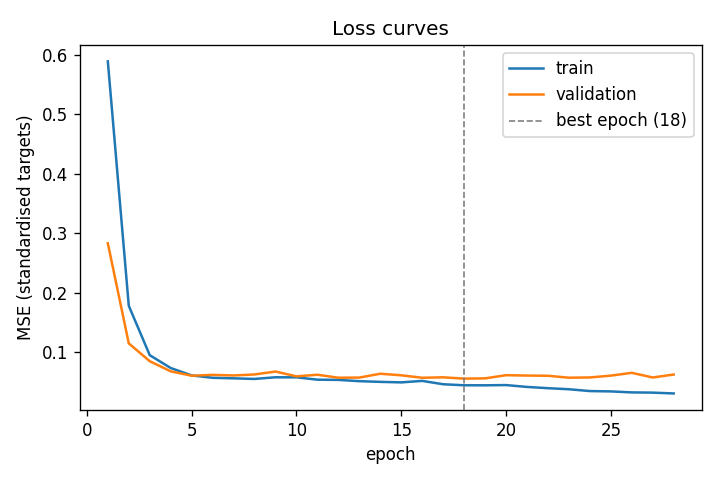

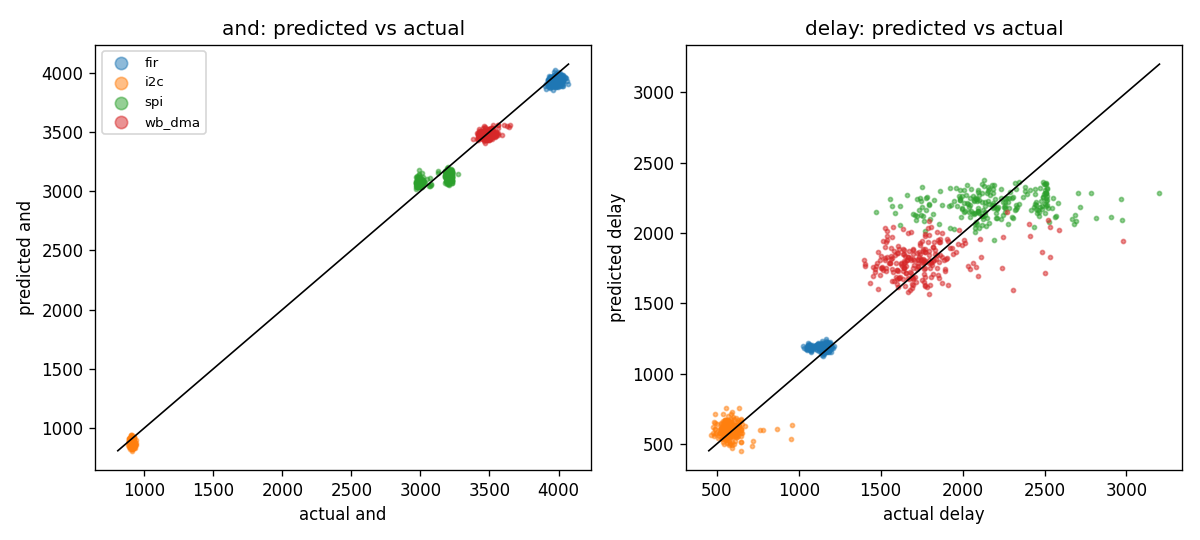

In [6]:
# Show the results of the latest run
import json
from IPython.display import Image, display
run_dir = sorted(Path("/kaggle/working/runs").iterdir())[-1]
print(run_dir)
print(json.dumps(json.loads((run_dir / "test_metrics.json").read_text()), indent=2))
display(Image(str(run_dir / "loss_curve.png")))
display(Image(str(run_dir / "test_scatter.png")))